# Plant seedlings: crop or weed, from one photo

**Ahmad Hassan** | AI Engineer · Live app: [SproutCheck](https://sproutcheck-seedling-classifier-application.streamlit.app/) ·
App code: [sproutcheck-seedling-classifier-application](https://github.com/ahmadhassan-aiops/sproutcheck-seedling-classifier-application)

A farm robot or an agronomist needs to tell a young crop from a weed early. This notebook names 12 species from a
top-down photo of a seedling: three crops (maize, common wheat, sugar beet) and nine weeds.

**Result.** EfficientNet-B0 fine-tuned from ImageNet weights names **97.2%** of 713 held-out test
photos correctly (macro F1 **0.969**), against 82.9% for frozen features with logistic regression and 77%
for the first version's small CNN. The weakest species is black-grass (80%), mostly
confused with loose silky-bent, another grass. Exported to ONNX (16.08 MB), it runs on CPU in the app.

## What changed from the first version

- **A small CNN on 64 x 64 images**, trained from scratch, reached 77% test accuracy; its first model never once named
  black-grass. The new models start from ImageNet weights and see 160 x 160 images.
- **A 10% test set** (about 20 photos for the rarest species) and no baseline. The test set is now 15% (713 photos),
  scored once after choosing on a separate validation set, with a frozen-feature baseline.
- **Three identical photos** could fall on both sides of the split; they are kept once.
- **Augmentation** was a single 90-degree rotation range in the second model; top-down seedlings have no up or down,
  so training now uses full rotations, flips, crops and colour shifts.
- Course instruction cells and a Colab Drive path were removed. The colour conversion from BGR to RGB was right and
  is kept.

## 1. The data

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import train_test_split

HERE = Path.cwd()
raw = np.load(HERE / "images.npy")
labels_raw = pd.read_csv(HERE / "Labels.csv")["Label"].to_numpy()
print(raw.shape, raw.dtype)
print(pd.Series(labels_raw).value_counts().to_string())

(4750, 128, 128, 3) uint8
Loose Silky-bent             654
Common Chickweed             611
Scentless Mayweed            516
Small-flowered Cranesbill    496
Fat Hen                      475
Charlock                     390
Sugar beet                   385
Cleavers                     287
Black-grass                  263
Shepherds Purse              231
Common wheat                 221
Maize                        221


Exact duplicates removed: 3


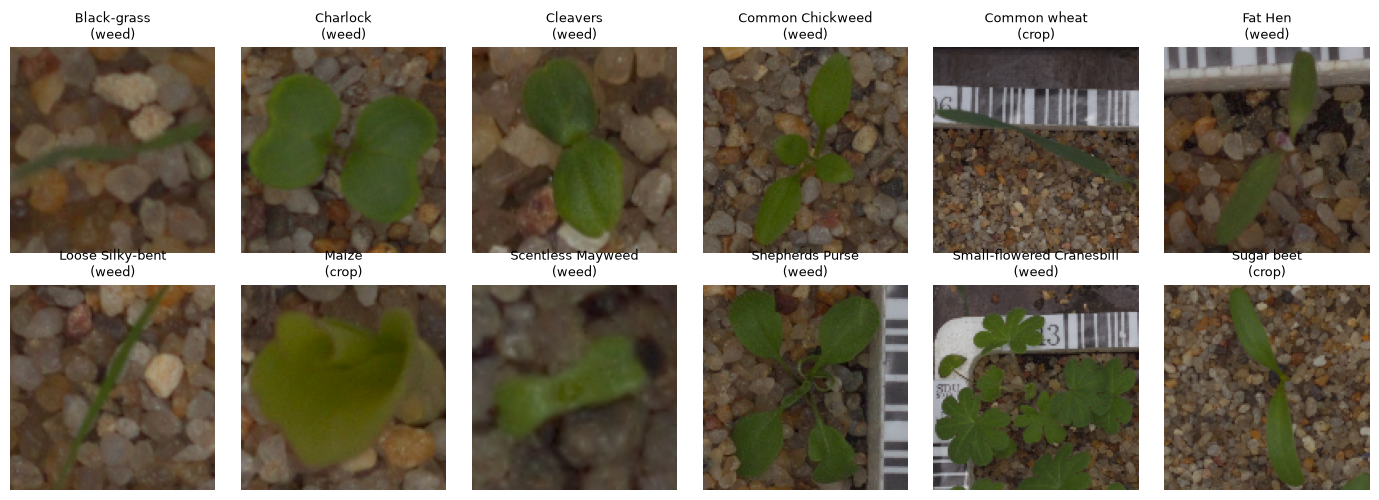

In [2]:
import hashlib

x_all = raw[..., ::-1].copy()   # stored BGR; RGB from here on
seen, keep = set(), []
for i in range(len(x_all)):
    h = hashlib.md5(x_all[i].tobytes()).hexdigest()
    if h not in seen:
        seen.add(h)
        keep.append(i)
x, labels = x_all[keep], labels_raw[keep]
print(f"Exact duplicates removed: {len(x_all) - len(x)}")
classes = sorted(set(labels))
crops = {"Maize", "Common wheat", "Sugar beet"}
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, c in zip(axes.ravel(), classes):
    ax.imshow(x[np.where(labels == c)[0][3]])
    ax.set_title(f"{c}\n({'crop' if c in crops else 'weed'})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Each photo is one seedling seen from above on soil, 128 x 128 pixels; some show a ruler or a tray edge. Classes are
uneven (loose silky-bent 654, common wheat and maize 221 each), so **macro F1**, which weighs every species equally,
chooses the model.

## 2. The split (as in `train.py`)

In [3]:
SEED = 42
y = np.array([classes.index(l) for l in labels])
idx = np.arange(len(y))
tr, te = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)
tr, va = train_test_split(tr, test_size=0.15 / 0.85, stratify=y[tr], random_state=SEED)
print(f"train {len(tr)} | validation {len(va)} | test {len(te)}")

train 3322 | validation 712 | test 713


## 3. Training

`train.py` (in the app repository) trains the candidates on CPU in about an hour; it is not re-run here. Its core:
the baseline is a frozen ImageNet MobileNetV3-Small with logistic regression on its features; MobileNetV3-Large and
EfficientNet-B0 are fine-tuned end to end for 14 epochs with AdamW, a one-cycle learning rate, label smoothing
0.1 and augmentation (rotation, flips, random resized crop, colour jitter), keeping the epoch with the best validation
macro F1. The confidence is calibrated with one temperature fitted on the validation photos.

Chosen: efficientnet_b0 | temperature 0.6444


,val accuracy,val macro F1
frozen_features_logreg,0.8258,0.8138
mobilenet_v3_large,0.9677,0.9664
efficientnet_b0,0.9747,0.9758


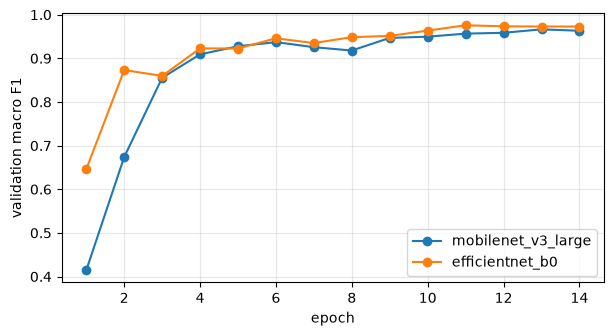

In [4]:
meta = json.loads((HERE / "model" / "metadata.json").read_text(encoding="utf-8"))
rows = {k: {"val accuracy": v["val"]["accuracy"], "val macro F1": v["val"]["macro_f1"]} for k, v in meta["results"].items()}
print("Chosen:", meta["chosen"], "| temperature", meta["temperature"])
display(pd.DataFrame(rows).T)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in ["mobilenet_v3_large", "efficientnet_b0"]:
    h = pd.DataFrame(meta["results"][k]["history"])
    ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro F1"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## 4. The test set, scored again with the exported model

The app runs the ONNX file, not PyTorch. Here the 713 test photos are prepared the way the app prepares a photo and
scored with that file, independently of the training run.

In [5]:
import onnxruntime as ort
from PIL import Image

sess = ort.InferenceSession(str(HERE / "model" / "sproutcheck.onnx"), providers=["CPUExecutionProvider"])
size, mean, std = meta["input_size"], np.array(meta["mean"]).reshape(3, 1, 1), np.array(meta["std"]).reshape(3, 1, 1)

def prepare(img):
    a = np.asarray(Image.fromarray(img).resize((size, size), Image.BILINEAR), dtype=np.float32).transpose(2, 0, 1) / 255
    return ((a - mean) / std).astype(np.float32)

logits = np.concatenate([sess.run(None, {"image": np.stack([prepare(x[i]) for i in te[k:k + 64]])})[0]
                         for k in range(0, len(te), 64)])
z = logits / meta["temperature"]
prob = np.exp(z - z.max(1, keepdims=True)); prob /= prob.sum(1, keepdims=True)
pred, truth = prob.argmax(1), y[te]
print(f"accuracy {accuracy_score(truth, pred):.4f} | macro F1 {f1_score(truth, pred, average='macro'):.4f} "
      f"(training run reported {meta['test']['accuracy']} / {meta['test']['macro_f1']})")
pd.Series(recall_score(truth, pred, average=None), index=classes).sort_values().round(3).to_frame("recall")

accuracy 0.9719 | macro F1 0.9692 (training run reported 0.9719 / 0.9692)


,recall
Black-grass,0.795
Loose Silky-bent,0.949
Common wheat,0.970
Shepherds Purse,0.971
Cleavers,0.977
Fat Hen,0.986
Small-flowered Cranesbill,0.986
Scentless Mayweed,0.987
Common Chickweed,0.989
Charlock,1.000


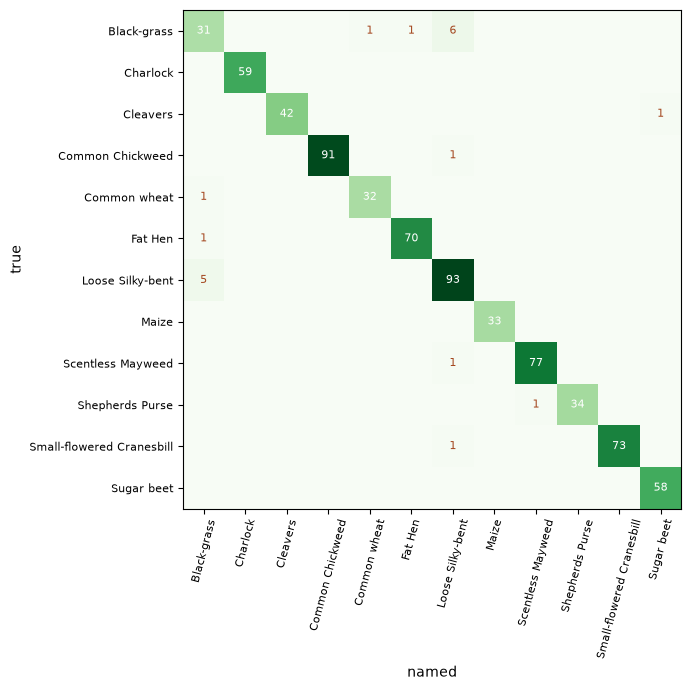

Crops called weeds: 1 of 124 | weeds called crops: 2 of 589


In [6]:
cm = confusion_matrix(truth, pred)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(12), classes, rotation=75, fontsize=8); ax.set_yticks(range(12), classes, fontsize=8)
for i in range(12):
    for j in range(12):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if i == j else "#a4471f")
ax.set_xlabel("named"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()
crop = np.array([c in crops for c in classes])
print(f"Crops called weeds: {cm[np.ix_(crop, ~crop)].sum()} of {cm[crop].sum()} | weeds called crops: {cm[np.ix_(~crop, crop)].sum()} of {cm[~crop].sum()}")

The mistakes are almost all between the two grasses: black-grass and loose silky-bent look alike as seedlings (thin
blades, no broad leaves), and the photos are only 128 pixels. Mixing a crop with a weed is rare: the decision the app
shows first (keep or remove) is wrong far less often than the species name.

## 5. Is the confidence honest?

In [7]:
conf = prob.max(1)
bands = pd.cut(conf, [0, .6, .8, .95, 1.0001], right=False, labels=["<60%", "60-80%", "80-95%", "95-100%"])
pd.DataFrame({"photos": pd.Series(bands).value_counts(sort=False),
              "average confidence": pd.Series(conf).groupby(bands, observed=False).mean().round(3),
              "named right": pd.Series(pred == truth).groupby(bands, observed=False).mean().round(3)})

,photos,average confidence,named right
<60%,6,0.526,0.833
60-80%,12,0.725,0.500
80-95%,37,0.899,0.757
95-100%,658,0.990,0.994


Most photos get 95% or more, and those are right about 99% of the time. Below that the model is less reliable than
its number suggests, so the app says "check by eye" under 80% and shows the runner-up when it is a real possibility.

## 6. The photos it gets wrong

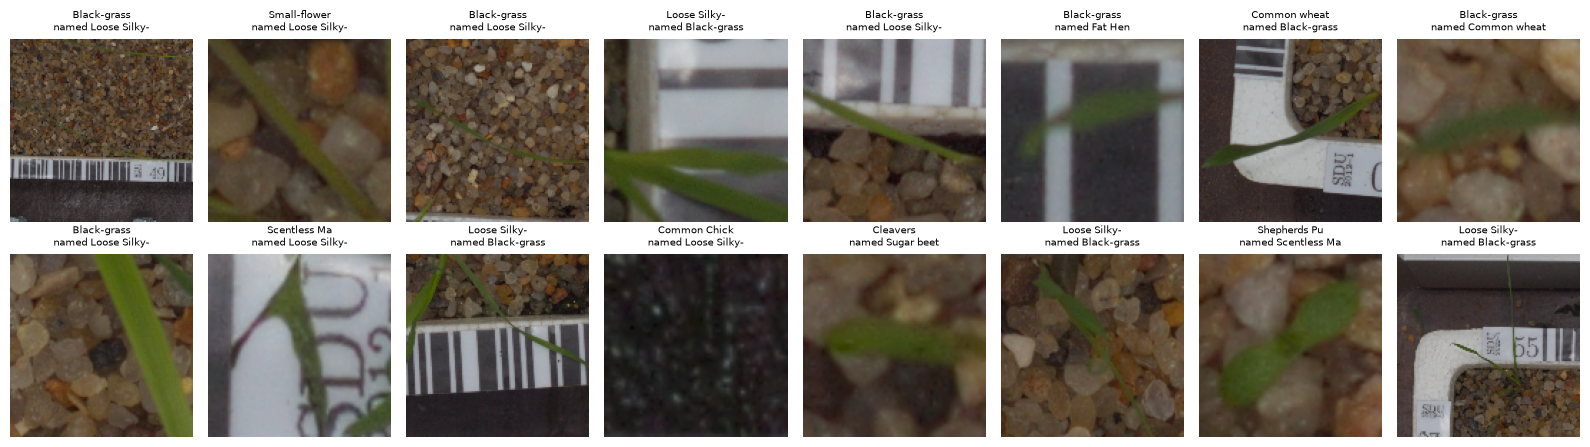

20 of 713 test photos named wrongly


In [8]:
wrong = np.where(pred != truth)[0]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, k in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x[te[k]]); ax.axis("off")
    ax.set_title(f"{classes[truth[k]][:12]}\nnamed {classes[pred[k]][:12]}", fontsize=7)
for ax in axes.ravel()[len(wrong[:16]):]:
    ax.axis("off")
plt.tight_layout(); plt.show()
print(f"{len(wrong)} of {len(te)} test photos named wrongly")

## Conclusions

- Transfer learning moves this task from 77% to **97.2%** test accuracy (macro F1 0.969), and
  the weakest species (black-grass) at 79.5% recall.
- The remaining errors are between two grasses; crop-or-weed mistakes are rare.
- A 16 MB ONNX model on CPU is enough for an app: training needs a GPU or an hour of CPU, using the model does not.

**Limits.** These are lab-style photos: one seedling, from above, on soil in a tray. Field photos, side views or several
plants will score lower, and any plant outside the twelve species still gets one of these names.